# MobileNetV3-Small — Cosine + Augment (gabungan)

Paper: Yong, L., Ma, L., Sun, D., & Du, L. (2023). *Application of MobileNetV2 to waste classification.*
PLOS ONE 18(3): e0282336. <https://doi.org/10.1371/journal.pone.0282336>

Notebook ini menjalankan **MobileNetV3-Small** dengan **gabungan resep Cosine (B) dan Augment (C)**
pada dataset, split, dan protokol training yang sama dengan eksperimen sebelumnya.
File ini **baru** dan tidak menimpa artefak/hasil varian A/B/C yang sudah ada.

Konfigurasi gabungan (`mobilenetv3small_cosine_aug`):
- Scheduler: **cosine annealing** (dari B)
- Label smoothing: **0.1**, weight decay: **1e-4** (dari B)
- Augmentasi train: **RandomResizedCrop + Flip + TrivialAugmentWide + ColorJitter + RandomErasing** (dari C)
- Class weight: tidak (mengikuti B), cross-entropy dengan label smoothing

## 1. Setup dan konfigurasi

In [1]:
# ---------------------------------------------------------------------------
# Auto-install dependencies. Packages that are already installed are untouched.
# ---------------------------------------------------------------------------
from __future__ import annotations

import importlib.util
import subprocess
import sys


def module_available(name: str) -> bool:
    return importlib.util.find_spec(name) is not None


def pip_install(*packages: str, index_url: str | None = None) -> bool:
    command = [sys.executable, "-m", "pip", "install", "-q"]
    if index_url:
        command += ["--index-url", index_url]
    command += list(packages)
    print("    $", " ".join(command))
    try:
        return subprocess.run(command, check=False).returncode == 0
    except Exception as exc:
        print(f"[warn] pip install failed for {' '.join(packages)}: {exc}")
        return False


def ensure(packages: dict[str, str]) -> list[str]:
    missing = [pkg for pkg, mod in packages.items() if not module_available(mod)]
    if not missing:
        return []
    print(f"[setup] installing: {', '.join(missing)}")
    for package in missing:
        pip_install(package)
    still_missing = [pkg for pkg in missing if not module_available(packages[pkg])]
    if still_missing:
        print("[warn] could not install: " + ", ".join(still_missing))
    return still_missing


ensure({
    "numpy": "numpy",
    "pandas": "pandas",
    "matplotlib": "matplotlib",
    "seaborn": "seaborn",
    "scikit-learn": "sklearn",
    "Pillow": "PIL",
    "tqdm": "tqdm",
    "ipywidgets": "ipywidgets",
})

if not module_available("torch") or not module_available("torchvision"):
    print("[setup] installing torch and torchvision")
    installed = pip_install(
        "torch", "torchvision", index_url="https://download.pytorch.org/whl/cpu"
    )
    if not installed and (not module_available("torch") or not module_available("torchvision")):
        print("[setup] retrying with the default PyPI index")
        pip_install("torch", "torchvision")

print("[setup] dependency check done")

[setup] dependency check done


In [2]:
from __future__ import annotations

import copy
import json
import math
import os
import random
import sys
import time
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image, ImageFile
try:
    from ipywidgets import IProgress  # noqa: F401
    from tqdm.auto import tqdm
except Exception:
    from tqdm import tqdm
from IPython.display import display

import torch
import torch.nn as nn
import torch.optim as optim
from torch.optim import lr_scheduler
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    top_k_accuracy_score,
)

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({
    "figure.dpi": 110,
    "savefig.dpi": 200,
    "axes.unicode_minus": False,
})

SEED = 42


def seed_everything(seed: int = SEED) -> None:
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False


seed_everything()


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "outputs").is_dir() and (candidate / "Datasets").is_dir():
            return candidate
    return start


REPO_ROOT = find_repo_root(Path.cwd().resolve())
OUTPUT_DIR = REPO_ROOT / "outputs"
SPLIT_DIR = OUTPUT_DIR / "splits"
MODEL_DIR = OUTPUT_DIR / "models"
RESULT_DIR = OUTPUT_DIR / "results"
FIGURE_DIR = OUTPUT_DIR / "figures"
for _d in (OUTPUT_DIR, SPLIT_DIR, MODEL_DIR, RESULT_DIR, FIGURE_DIR):
    _d.mkdir(parents=True, exist_ok=True)

DATA_ROOT = Path(
    os.environ.get("TRASH_DATA_DIR", REPO_ROOT / "Datasets" / "images" / "images")
).resolve()

# Paper defaults from train_245_class.py, kept identical for a fair comparison.
IMG_SIZE = 224
BATCH_SIZE = 42
NUM_EPOCHS = 50
LEARNING_RATE = 1e-3
MOMENTUM = 0.9
STEP_SIZE = 7
GAMMA = 0.1
NUM_WORKERS = 0
PRETRAINED = os.environ.get("TRASH_REPRO_PRETRAINED", "1") == "1"
TEST_BATCH_SIZE = 128

# Early stopping: hentikan training jika validation accuracy tidak membaik.
EARLY_STOP_PATIENCE = 10
EARLY_STOP_MIN_EPOCHS = 10

QUICK_TEST = os.environ.get("TRASH_REPRO_QUICK", "0") == "1"
TRAIN_PER_CLASS = VAL_PER_CLASS = TEST_PER_CLASS = None
if QUICK_TEST:
    NUM_EPOCHS = 1
    BATCH_SIZE = 16
    PRETRAINED = False
    TRAIN_PER_CLASS, VAL_PER_CLASS, TEST_PER_CLASS = 20, 5, 5
    EARLY_STOP_PATIENCE = 3
    EARLY_STOP_MIN_EPOCHS = 1

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print(f"Python           : {sys.version.split()[0]}")
print(f"PyTorch          : {torch.__version__}")
print(f"Device           : {DEVICE}")
print(f"Repo root        : {REPO_ROOT}")
print(f"Data root        : {DATA_ROOT} (exists={DATA_ROOT.exists()})")
print(f"Output folder    : {OUTPUT_DIR}")
print(f"Quick test       : {QUICK_TEST}")
print(f"Pretrained weights: {PRETRAINED}")
print(f"Early stopping   : patience {EARLY_STOP_PATIENCE} epoch (min {EARLY_STOP_MIN_EPOCHS})")

Python           : 3.12.3
PyTorch          : 2.15.0+cu132
Device           : cuda
Repo root        : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16
Data root        : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/Datasets/images/images (exists=True)
Output folder    : /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs
Quick test       : False
Pretrained weights: True
Early stopping   : patience 10 epoch (min 10)


## 2. Dataset dan split

Split 8:1:1 dibaca ulang dari `outputs/splits/all.csv` (identik dengan eksperimen lain).

In [3]:
# 30 fine classes and the 3-class grouping.
CLASS_NAMES = [
    "aerosol_cans", "aluminum_food_cans", "aluminum_soda_cans",
    "cardboard_boxes", "cardboard_packaging", "clothing",
    "coffee_grounds", "disposable_plastic_cutlery", "eggshells",
    "food_waste", "glass_beverage_bottles", "glass_cosmetic_containers",
    "glass_food_jars", "magazines", "newspaper", "office_paper",
    "paper_cups", "plastic_cup_lids", "plastic_detergent_bottles",
    "plastic_food_containers", "plastic_shopping_bags", "plastic_soda_bottles",
    "plastic_straws", "plastic_trash_bags", "plastic_water_bottles",
    "shoes", "steel_food_cans", "styrofoam_cups",
    "styrofoam_food_containers", "tea_bags",
]
CLASS_TO_IDX = {name: i for i, name in enumerate(CLASS_NAMES)}
NUM_CLASSES = len(CLASS_NAMES)

MAJOR_NAMES = ["Kitchen waste", "Recyclable waste", "Other waste"]
MAJOR_TO_IDX = {name: i for i, name in enumerate(MAJOR_NAMES)}

CLASS_TO_MAJOR = {
    "coffee_grounds": "Kitchen waste", "eggshells": "Kitchen waste",
    "food_waste": "Kitchen waste", "tea_bags": "Kitchen waste",
    "aerosol_cans": "Recyclable waste", "aluminum_food_cans": "Recyclable waste",
    "aluminum_soda_cans": "Recyclable waste", "cardboard_boxes": "Recyclable waste",
    "cardboard_packaging": "Recyclable waste", "clothing": "Recyclable waste",
    "glass_beverage_bottles": "Recyclable waste", "glass_cosmetic_containers": "Recyclable waste",
    "glass_food_jars": "Recyclable waste", "magazines": "Recyclable waste",
    "newspaper": "Recyclable waste", "office_paper": "Recyclable waste",
    "paper_cups": "Recyclable waste", "plastic_detergent_bottles": "Recyclable waste",
    "plastic_food_containers": "Recyclable waste", "plastic_shopping_bags": "Recyclable waste",
    "plastic_soda_bottles": "Recyclable waste", "plastic_water_bottles": "Recyclable waste",
    "shoes": "Recyclable waste", "steel_food_cans": "Recyclable waste",
    "disposable_plastic_cutlery": "Other waste", "plastic_cup_lids": "Other waste",
    "plastic_straws": "Other waste", "plastic_trash_bags": "Other waste",
    "styrofoam_cups": "Other waste", "styrofoam_food_containers": "Other waste",
}
assert not (set(CLASS_NAMES) - set(CLASS_TO_MAJOR)), "Missing major-class mapping"
print(f"Classes: {NUM_CLASSES}")
print(pd.Series(CLASS_TO_MAJOR).value_counts().to_string())

Classes: 30
Recyclable waste    20
Other waste          6
Kitchen waste        4


In [4]:
assert DATA_ROOT.exists(), f"Dataset folder not found: {DATA_ROOT}. Set TRASH_DATA_DIR."
missing_dirs = [name for name in CLASS_NAMES if not (DATA_ROOT / name).is_dir()]
assert not missing_dirs, f"Missing class folders under {DATA_ROOT}: {missing_dirs}"

SPLIT_MANIFEST = SPLIT_DIR / "all.csv"
if not SPLIT_MANIFEST.exists():
    raise FileNotFoundError(
        f"{SPLIT_MANIFEST} not found. Jalankan notebook reproduksi/eksplorasi lain untuk menulis manifest split."
    )

df = pd.read_csv(SPLIT_MANIFEST)
df = df[["rel_path", "class_name", "source_group", "md5", "split", "label"]]
df["label"] = df["class_name"].map(CLASS_TO_IDX).astype(int)

if QUICK_TEST:
    limits = {"train": TRAIN_PER_CLASS, "val": VAL_PER_CLASS, "test": TEST_PER_CLASS}
    parts = []
    for (split_name, _class_name), group in df.groupby(["split", "class_name"], sort=True):
        n_total = limits[split_name]
        n_groups = max(1, group["source_group"].nunique())
        n_per_group = max(1, math.ceil(n_total / n_groups))
        for _source_group, subgroup in group.groupby("source_group", sort=True):
            parts.append(subgroup.head(n_per_group))
    df = pd.concat(parts, ignore_index=True)
    trimmed = []
    for (split_name, _class_name), group in df.groupby(["split", "class_name"], sort=True):
        trimmed.append(group.head(limits[split_name]))
    df = pd.concat(trimmed, ignore_index=True)

df = df.sort_values(["split", "class_name", "rel_path"]).reset_index(drop=True)

print("Split sizes:")
print(df["split"].value_counts().reindex(["train", "val", "test"]).to_string())
assert set(df["split"]) == {"train", "val", "test"}
assert df.groupby("split")["class_name"].nunique().eq(NUM_CLASSES).all()
assert df.groupby("md5")["split"].nunique().eq(1).all(), "Duplicate image crossed a split."

Split sizes:
split
train    9006
val      1124
test     1133


## 3. Transform dan loader

In [5]:
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

# Gabungan cosine+augment: pakai augmentasi kuat (seperti varian C)
aug_train_transform = transforms.Compose([
    transforms.RandomResizedCrop(IMG_SIZE),
    transforms.RandomHorizontalFlip(),
    transforms.TrivialAugmentWide(),
    transforms.ColorJitter(0.2, 0.2, 0.2, 0.05),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    transforms.RandomErasing(p=0.15, scale=(0.02, 0.15)),
])

eval_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class TrashDataset(Dataset):
    """Manifest-backed image dataset for the Kaggle waste folder layout."""

    def __init__(self, frame: pd.DataFrame, root: Path, transform=None):
        self.frame = frame.reset_index(drop=True)
        self.root = Path(root)
        self.transform = transform

    def __len__(self) -> int:
        return len(self.frame)

    def __getitem__(self, index: int):
        row = self.frame.iloc[index]
        with Image.open(self.root / row["rel_path"]) as img:
            image = img.convert("RGB")
        if self.transform is not None:
            image = self.transform(image)
        return image, int(row["label"])


def seed_worker(worker_id: int) -> None:
    worker_seed = torch.initial_seed() % (2 ** 32)
    np.random.seed(worker_seed)
    random.seed(worker_seed)


def make_loader(frame: pd.DataFrame, training: bool, batch_size: int, transform=None) -> DataLoader:
    dataset = TrashDataset(
        frame,
        DATA_ROOT,
        transform=transform if transform is not None else (train_transform if training else eval_transform),
    )
    drop_last = training and len(dataset) >= batch_size and len(dataset) % batch_size == 1
    generator = torch.Generator()
    generator.manual_seed(SEED)
    return DataLoader(
        dataset,
        batch_size=batch_size,
        shuffle=training,
        num_workers=NUM_WORKERS,
        pin_memory=torch.cuda.is_available(),
        drop_last=drop_last,
        persistent_workers=NUM_WORKERS > 0,
        worker_init_fn=seed_worker,
        generator=generator,
    )


train_df = df[df["split"] == "train"].reset_index(drop=True)
val_df = df[df["split"] == "val"].reset_index(drop=True)
test_df = df[df["split"] == "test"].reset_index(drop=True)

val_loader = make_loader(val_df, training=False, batch_size=BATCH_SIZE)
test_loader = make_loader(test_df, training=False, batch_size=TEST_BATCH_SIZE)

print(f"Train: {len(train_df):,} images")
print(f"Val  : {len(val_df):,} images, {len(val_loader)} batches")
print(f"Test : {len(test_df):,} images, {len(test_loader)} batches")

Train: 9,006 images
Val  : 1,124 images, 27 batches
Test : 1,133 images, 9 batches


## 4. Model MobileNetV3-Small

In [6]:
def count_parameters(model: nn.Module) -> int:
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def build_mobilenet_v3_small(num_classes: int, pretrained: bool = True) -> nn.Module:
    weights = "IMAGENET1K_V1" if pretrained else None
    model = models.mobilenet_v3_small(weights=weights)
    in_features = model.classifier[3].in_features
    model.classifier[3] = nn.Linear(in_features, num_classes)
    return model


print("MobileNetV3-Small builder siap.")

MobileNetV3-Small builder siap.


## 5. Training loop

In [7]:
def train_model(
    model,
    train_loader,
    val_loader,
    criterion,
    optimizer,
    scheduler,
    epochs,
    device,
    checkpoint_path,
    history_path,
    model_name,
    arch,
    extra_config=None,
    full_model_path=None,
    early_stopping_patience=None,
    early_stop_min_epochs=0,
):
    since = time.time()
    best_model_wts = copy.deepcopy(model.state_dict())
    best_val_acc = -1.0
    best_epoch = 0
    epochs_without_improvement = 0
    stopped_epoch = 0
    history = []
    dataloaders = {"train": train_loader, "val": val_loader}
    dataset_sizes = {phase: len(loader.dataset) for phase, loader in dataloaders.items()}

    for epoch in range(1, epochs + 1):
        print(f"Epoch {epoch}/{epochs}")
        print("-" * 10)
        epoch_start = time.time()
        epoch_losses = {}
        epoch_accs = {}
        improved_this_epoch = False

        for phase in ["train", "val"]:
            model.train() if phase == "train" else model.eval()

            running_loss = 0.0
            running_corrects = 0
            loader = dataloaders[phase]

            progress = tqdm(
                total=dataset_sizes[phase],
                desc=f"{model_name} {phase} {epoch}/{epochs}",
                leave=False,
            )
            for inputs, labels in loader:
                inputs = inputs.to(device, non_blocking=True)
                labels = labels.to(device, non_blocking=True)

                optimizer.zero_grad()

                with torch.set_grad_enabled(phase == "train"):
                    outputs = model(inputs)
                    _, preds = torch.max(outputs, 1)
                    loss = criterion(outputs, labels)

                    if phase == "train":
                        loss.backward()
                        optimizer.step()

                running_loss += loss.item() * inputs.size(0)
                running_corrects += torch.sum(preds == labels.data)
                progress.update(inputs.size(0))
            progress.close()

            if phase == "train" and scheduler is not None:
                scheduler.step()

            epoch_loss = running_loss / dataset_sizes[phase]
            epoch_acc = running_corrects.double() / dataset_sizes[phase]
            epoch_losses[phase] = float(epoch_loss)
            epoch_accs[phase] = float(epoch_acc)
            print(f"{phase} Loss: {epoch_loss:.4f} Acc: {epoch_acc:.4f}")

            if phase == "val" and epoch_acc > best_val_acc:
                best_val_acc = float(epoch_acc)
                best_epoch = epoch
                improved_this_epoch = True
                best_model_wts = copy.deepcopy(model.state_dict())
                checkpoint = {
                    "arch": arch,
                    "model_name": model_name,
                    "state_dict": model.state_dict(),
                    "class_names": CLASS_NAMES,
                    "major_names": MAJOR_NAMES,
                    "class_to_major": CLASS_TO_MAJOR,
                    "img_size": IMG_SIZE,
                    "mean": IMAGENET_MEAN,
                    "std": IMAGENET_STD,
                    "epoch": epoch,
                    "val_acc": float(epoch_acc),
                    "val_loss": float(epoch_loss),
                    "config": {
                        "seed": SEED,
                        "batch_size": BATCH_SIZE,
                        "epochs": epochs,
                        "pretrained": PRETRAINED,
                        **(extra_config or {}),
                    },
                }
                torch.save(checkpoint, checkpoint_path)

        if improved_this_epoch:
            epochs_without_improvement = 0
        else:
            epochs_without_improvement += 1

        current_lr = optimizer.param_groups[0]["lr"]
        record = {
            "epoch": epoch,
            "train_loss": epoch_losses["train"],
            "train_acc": epoch_accs["train"],
            "val_loss": epoch_losses["val"],
            "val_acc": epoch_accs["val"],
            "lr": float(current_lr),
            "time_sec": float(time.time() - epoch_start),
            "best_val_acc": best_val_acc,
        }
        history.append(record)
        pd.DataFrame(history).to_csv(history_path, index=False)

        print(
            f"[{model_name}] epoch {epoch:02d}/{epochs} | "
            f"train loss {record['train_loss']:.4f} acc {record['train_acc']:.4f} | "
            f"val loss {record['val_loss']:.4f} acc {record['val_acc']:.4f} | "
            f"lr {current_lr:.2e} | {record['time_sec']:.1f}s"
        )
        print()

        if (
            early_stopping_patience is not None
            and epoch >= early_stop_min_epochs
            and epochs_without_improvement >= early_stopping_patience
        ):
            stopped_epoch = epoch
            print(
                f"Early stopping at epoch {epoch}: validation accuracy tidak membaik "
                f"selama {early_stopping_patience} epoch."
            )
            break

    time_elapsed = time.time() - since
    print(f"Training complete in {time_elapsed // 60:.0f}m {time_elapsed % 60:.0f}s")
    print(f"Epochs run: {len(history)}/{epochs}")
    if stopped_epoch:
        print(f"Stopped early at epoch {stopped_epoch}")
    print(f"Best val Acc: {best_val_acc:.4f} at epoch {best_epoch}")
    model.load_state_dict(best_model_wts)
    if full_model_path is not None:
        torch.save(model, full_model_path)
        print(f"Full model: {full_model_path}")
    print(f"Checkpoint: {checkpoint_path}")
    return history, best_val_acc, best_epoch


def load_checkpoint(path, device):
    try:
        return torch.load(path, map_location=device, weights_only=True)
    except TypeError:
        return torch.load(path, map_location=device)
    except Exception:
        return torch.load(path, map_location=device, weights_only=False)

## 6. Varian training: Cosine + Augment (gabungan)

Prefix artefak: `mobilenetv3small_cosine_aug_*` (tidak menimpa varian A/B/C).

In [8]:
VARIANTS = {
    "mobilenetv3small_cosine_aug": {
        "label": "Cosine + Augment (gabungan)",
        "transform": aug_train_transform,  # TrivialAugmentWide + ColorJitter + RandomErasing
        "label_smoothing": 0.1,
        "weight_decay": 1e-4,
        "scheduler": "cosine",
        "class_weight": False,
        "augmentation": "rrc+flip+trivialaugment+colorjitter+randomerasing",
    },
}


def build_criterion(spec):
    if spec.get("class_weight"):
        counts = train_df["class_name"].value_counts().reindex(CLASS_NAMES).to_numpy()
        weights = torch.tensor(
            counts.sum() / (NUM_CLASSES * counts), dtype=torch.float32, device=DEVICE
        )
        return nn.CrossEntropyLoss(weight=weights, label_smoothing=spec.get("label_smoothing", 0.0))
    return nn.CrossEntropyLoss(label_smoothing=spec.get("label_smoothing", 0.0))


def build_scheduler(optimizer, spec, epochs):
    if spec.get("scheduler") == "cosine":
        return lr_scheduler.CosineAnnealingLR(optimizer, T_max=epochs)
    return lr_scheduler.StepLR(optimizer, step_size=STEP_SIZE, gamma=GAMMA)


for name, spec in VARIANTS.items():
    print(f"{name:30s} | {spec['label']}")
    print(f"  scheduler={spec['scheduler']} | ls={spec['label_smoothing']} | wd={spec['weight_decay']} | class_weight={spec['class_weight']}")
    print(f"  augmentation={spec['augmentation']}")

mobilenetv3small_cosine_aug    | Cosine + Augment (gabungan)
  scheduler=cosine | ls=0.1 | wd=0.0001 | class_weight=False
  augmentation=rrc+flip+trivialaugment+colorjitter+randomerasing


In [9]:
runs = {}

for name, spec in VARIANTS.items():
    print("=" * 78)
    print(f"Training {name} ({spec['label']})")
    print("=" * 78)

    variant_train_loader = make_loader(
        train_df, training=True, batch_size=BATCH_SIZE, transform=spec["transform"]
    )
    variant_model = build_mobilenet_v3_small(NUM_CLASSES, pretrained=PRETRAINED).to(DEVICE)
    variant_criterion = build_criterion(spec)
    variant_optimizer = optim.SGD(
        variant_model.parameters(),
        lr=LEARNING_RATE,
        momentum=MOMENTUM,
        weight_decay=spec.get("weight_decay", 0.0),
    )
    variant_scheduler = build_scheduler(variant_optimizer, spec, NUM_EPOCHS)

    checkpoint_path = MODEL_DIR / f"{name}_trash30_best.pt"
    full_model_path = MODEL_DIR / f"{name}_trash30_full.pt"
    history_path = RESULT_DIR / f"{name}_history.csv"

    variant_history, variant_best_acc, variant_best_epoch = train_model(
        model=variant_model,
        train_loader=variant_train_loader,
        val_loader=val_loader,
        criterion=variant_criterion,
        optimizer=variant_optimizer,
        scheduler=variant_scheduler,
        epochs=NUM_EPOCHS,
        device=DEVICE,
        checkpoint_path=checkpoint_path,
        full_model_path=full_model_path,
        history_path=history_path,
        model_name=name,
        arch="mobilenet_v3_small",
        extra_config={
            "variant": spec["label"],
            "learning_rate": LEARNING_RATE,
            "momentum": MOMENTUM,
            "weight_decay": spec.get("weight_decay", 0.0),
            "label_smoothing": spec.get("label_smoothing", 0.0),
            "scheduler": spec.get("scheduler", "step"),
            "class_weight": spec.get("class_weight", False),
            "augmentation": spec.get("augmentation", ""),
        },
        early_stopping_patience=EARLY_STOP_PATIENCE,
        early_stop_min_epochs=EARLY_STOP_MIN_EPOCHS,
    )

    runs[name] = {
        "label": spec["label"],
        "spec": spec,
        "model": variant_model,
        "history": variant_history,
        "best_val_acc": variant_best_acc,
        "best_epoch": variant_best_epoch,
        "checkpoint": checkpoint_path,
        "full_model": full_model_path,
        "history_csv": history_path,
    }
    print(f"{name}: best val acc {variant_best_acc:.4f} @ epoch {variant_best_epoch}")

print("\nSelesai:", ", ".join(runs))

Training mobilenetv3small_cosine_aug (Cosine + Augment (gabungan))


Epoch 1/50
----------


mobilenetv3small_cosine_aug train 1/50:   0%|                                                                                                                    | 0/9006 [00:00<?, ?it/s]

mobilenetv3small_cosine_aug train 1/50:   0%|▍                                                                                                          | 42/9006 [00:00<02:08, 69.92it/s]

mobilenetv3small_cosine_aug train 1/50:   1%|▉                                                                                                         | 84/9006 [00:00<01:15, 117.82it/s]

mobilenetv3small_cosine_aug train 1/50:   1%|█▍                                                                                                       | 126/9006 [00:00<00:58, 151.79it/s]

... (10,855 outputs left out)

mobilenetv3small_cosine_aug val 47/50:  82%|███████████████████████████████████████████████████████████████████████████████████████▏                  | 924/1124 [00:01<00:00, 490.92it/s]

mobilenetv3small_cosine_aug val 47/50:  90%|██████████████████████████████████████████████████████████████████████████████████████████████▏          | 1008/1124 [00:02<00:00, 513.26it/s]

mobilenetv3small_cosine_aug val 47/50:  97%|██████████████████████████████████████████████████████████████████████████████████████████████████████   | 1092/1124 [00:02<00:00, 531.12it/s]

val Loss: 1.2473 Acc: 0.7909
[mobilenetv3small_cosine_aug] epoch 47/50 | train loss 1.3428 acc 0.7650 | val loss 1.2473 acc 0.7909 | lr 8.86e-06 | 48.5s

Early stopping at epoch 47: validation accuracy tidak membaik selama 10 epoch.
Training complete in 37m 21s
Epochs run: 47/50
Stopped early at epoch 47
Best val Acc: 0.7998 at epoch 37
Full model: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/mobilenetv3small_cosine_aug_trash30_full.pt
Checkpoint: /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/models/mobilenetv3small_cosine_aug_trash30_best.pt
mobilenetv3small_cosine_aug: best val acc 0.7998 @ epoch 37

Selesai: mobilenetv3small_cosine_aug


## 7. Kurva training

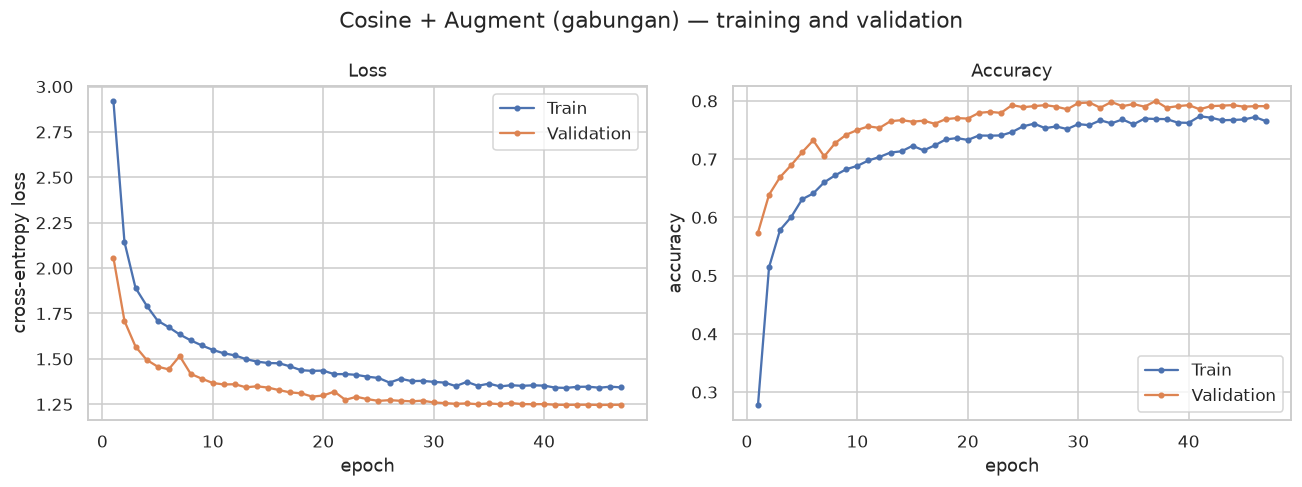

,epoch,train_loss,train_acc,val_loss,val_acc,lr,time_sec,best_val_acc
42,43,1.346025,0.766711,1.247319,0.791815,0.000048,49.559653,0.799822
43,44,1.346871,0.767266,1.247527,0.792705,0.000035,50.335279,0.799822
44,45,1.341137,0.768044,1.246211,0.790036,0.000024,48.738301,0.799822
45,46,1.347017,0.772263,1.246835,0.790925,0.000016,48.658221,0.799822
46,47,1.342828,0.765046,1.247287,0.790925,0.000009,48.486605,0.799822


In [10]:
def plot_training_curves(history, title: str, output_path: Path):
    frame = pd.DataFrame(history)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
    axes[0].plot(frame["epoch"], frame["train_loss"], marker="o", ms=3, label="Train")
    axes[0].plot(frame["epoch"], frame["val_loss"], marker="o", ms=3, label="Validation")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].set_title("Loss"); axes[0].legend()
    axes[1].plot(frame["epoch"], frame["train_acc"], marker="o", ms=3, label="Train")
    axes[1].plot(frame["epoch"], frame["val_acc"], marker="o", ms=3, label="Validation")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].set_title("Accuracy"); axes[1].legend()
    fig.suptitle(title)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


for name, run in runs.items():
    plot_training_curves(
        run["history"],
        f"{run['label']} — training and validation",
        FIGURE_DIR / f"{name}_curves.png",
    )
    display(pd.DataFrame(run["history"]).tail())

## 8. Evaluasi test

In [11]:
def jsonable(obj):
    if isinstance(obj, dict):
        return {str(k): jsonable(v) for k, v in obj.items()}
    if isinstance(obj, (list, tuple)):
        return [jsonable(v) for v in obj]
    if isinstance(obj, np.ndarray):
        return obj.tolist()
    if isinstance(obj, np.integer):
        return int(obj)
    if isinstance(obj, np.floating):
        return float(obj)
    if isinstance(obj, Path):
        return str(obj)
    return obj


def aggregate_major_probs(probs: np.ndarray, class_names):
    major_probs = np.zeros((probs.shape[0], len(MAJOR_NAMES)), dtype=np.float64)
    for class_idx, class_name in enumerate(class_names):
        major_probs[:, MAJOR_TO_IDX[CLASS_TO_MAJOR[class_name]]] += probs[:, class_idx]
    return major_probs


@torch.no_grad()
def predict_loader(model, loader, criterion, device):
    model.eval()
    all_probs, all_labels = [], []
    total_loss = 0.0
    total_samples = 0
    for images, labels in tqdm(loader, desc="Evaluating", leave=False):
        images = images.to(device, non_blocking=True)
        labels = labels.to(device, non_blocking=True)
        outputs = model(images)
        loss = criterion(outputs, labels)
        probs = torch.softmax(outputs, dim=1)
        all_probs.append(probs.cpu().numpy())
        all_labels.append(labels.cpu().numpy())
        total_loss += loss.item() * labels.size(0)
        total_samples += labels.size(0)
    if total_samples == 0:
        raise RuntimeError("Empty evaluation loader.")
    probs = np.concatenate(all_probs, axis=0)
    labels = np.concatenate(all_labels, axis=0)
    return probs, labels, total_loss / total_samples


def plot_confusion_matrix(cm, labels, title, output_path, normalize=True):
    cm = np.asarray(cm, dtype=np.float64)
    if normalize:
        row_sums = cm.sum(axis=1, keepdims=True)
        plot_cm = np.divide(cm, row_sums, out=np.zeros_like(cm), where=row_sums != 0)
        fmt = ".2f"
    else:
        plot_cm = cm
        fmt = "d"
    annot = len(labels) <= 12
    fig, ax = plt.subplots(figsize=(max(7, len(labels) * 0.48), max(6, len(labels) * 0.42)))
    sns.heatmap(
        plot_cm, annot=annot, fmt=fmt, cmap="Blues",
        xticklabels=labels, yticklabels=labels, ax=ax, cbar=True,
        linewidths=0.2 if annot else 0,
        annot_kws={"fontsize": 9} if annot else None,
    )
    ax.set_xlabel("predicted"); ax.set_ylabel("true"); ax.set_title(title)
    ax.tick_params(axis="x", rotation=90, labelsize=7)
    ax.tick_params(axis="y", rotation=0, labelsize=7)
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


def evaluate_and_save(model, loader, criterion, device, frame, model_key):
    probs, labels, loss = predict_loader(model, loader, criterion, device)
    preds = probs.argmax(axis=1)

    report_dict = classification_report(
        labels, preds, labels=np.arange(NUM_CLASSES), target_names=CLASS_NAMES,
        output_dict=True, zero_division=0,
    )
    cm = confusion_matrix(labels, preds, labels=np.arange(NUM_CLASSES))
    per_class_acc = np.divide(
        cm.diagonal(), cm.sum(axis=1),
        out=np.zeros(NUM_CLASSES, dtype=np.float64), where=cm.sum(axis=1) != 0,
    )

    major_probs = aggregate_major_probs(probs, CLASS_NAMES)
    major_true = frame["class_name"].map(lambda c: MAJOR_TO_IDX[CLASS_TO_MAJOR[c]]).to_numpy()
    major_pred = np.array([MAJOR_TO_IDX[CLASS_TO_MAJOR[CLASS_NAMES[int(i)]]] for i in preds])
    major_prob_pred = major_probs.argmax(axis=1)
    major_report = classification_report(
        major_true, major_pred, labels=np.arange(len(MAJOR_NAMES)),
        target_names=MAJOR_NAMES, output_dict=True, zero_division=0,
    )
    major_cm = confusion_matrix(major_true, major_pred, labels=np.arange(len(MAJOR_NAMES)))

    prediction_frame = frame[["rel_path", "class_name", "source_group"]].copy()
    prediction_frame["true_label"] = labels
    prediction_frame["pred_label"] = preds
    prediction_frame["pred_class"] = [CLASS_NAMES[i] for i in preds]
    prediction_frame["confidence"] = probs.max(axis=1)
    prediction_frame["correct"] = (labels == preds).astype(int)
    for class_idx, class_name in enumerate(CLASS_NAMES):
        prediction_frame[f"prob_{class_name}"] = probs[:, class_idx]
    prediction_frame.to_csv(RESULT_DIR / f"{model_key}_predictions.csv", index=False)

    metrics = {
        "model": model_key,
        "split": "test",
        "num_test": int(len(labels)),
        "accuracy": float(accuracy_score(labels, preds)),
        "loss": float(loss),
        "top3_accuracy": float(top_k_accuracy_score(labels, probs, k=min(3, NUM_CLASSES), labels=np.arange(NUM_CLASSES))),
        "macro_f1": float(report_dict["macro avg"]["f1-score"]),
        "weighted_f1": float(report_dict["weighted avg"]["f1-score"]),
        "per_class_accuracy": {name: float(per_class_acc[i]) for i, name in enumerate(CLASS_NAMES)},
        "group_accuracy": {str(group): float(sub["correct"].mean()) for group, sub in prediction_frame.groupby("source_group")},
        "classification_report": report_dict,
        "confusion_matrix": cm.tolist(),
        "major_accuracy": float(accuracy_score(major_true, major_pred)),
        "major_prob_accuracy": float(accuracy_score(major_true, major_prob_pred)),
        "major_report": major_report,
        "major_confusion_matrix": major_cm.tolist(),
        "major_class_names": MAJOR_NAMES,
        "class_names": CLASS_NAMES,
    }
    with open(RESULT_DIR / f"{model_key}_metrics.json", "w") as handle:
        json.dump(jsonable(metrics), handle, indent=2)

    pd.DataFrame(report_dict).T.to_csv(RESULT_DIR / f"{model_key}_classification_report.csv")
    pd.DataFrame(major_report).T.to_csv(RESULT_DIR / f"{model_key}_major_report.csv")
    pd.DataFrame(per_class_acc, index=CLASS_NAMES, columns=["accuracy"]).to_csv(
        RESULT_DIR / f"{model_key}_per_class_accuracy.csv"
    )

    print(f"\n{model_key} — test results")
    print(f"  loss              : {metrics['loss']:.4f}")
    print(f"  30-class accuracy : {metrics['accuracy'] * 100:.2f}%")
    print(f"  macro F1 (30)     : {metrics['macro_f1']:.4f}")
    print(f"  top-3 accuracy    : {metrics['top3_accuracy'] * 100:.2f}%")
    print(f"  3-class accuracy  : {metrics['major_accuracy'] * 100:.2f}%")
    print(f"  3-class prob agg  : {metrics['major_prob_accuracy'] * 100:.2f}%")
    for group, value in metrics["group_accuracy"].items():
        print(f"    {group:10s}: {value * 100:.2f}%")

    return metrics, probs, labels, preds, major_true, major_pred

In [12]:
eval_criterion = nn.CrossEntropyLoss()
evaluations = {}

for name, run in runs.items():
    eval_model = build_mobilenet_v3_small(NUM_CLASSES, pretrained=False).to(DEVICE)
    ckpt = load_checkpoint(run["checkpoint"], DEVICE)
    eval_model.load_state_dict(ckpt["state_dict"])
    eval_model.eval()
    print(f"\n{name}: checkpoint epoch {ckpt['epoch']} (val acc {ckpt['val_acc']:.4f})")

    (metrics, test_probs, test_labels, test_preds, major_true, major_pred) = evaluate_and_save(
        eval_model, test_loader, eval_criterion, DEVICE, test_df, model_key=name
    )
    evaluations[name] = {
        "metrics": metrics,
        "model": eval_model,
        "probabilities": test_probs,
        "labels": test_labels,
        "predictions": test_preds,
    }
    display(pd.DataFrame(metrics["major_report"]).T.round(3))


mobilenetv3small_cosine_aug: checkpoint epoch 37 (val acc 0.7998)


Evaluating:   0%|                                                                                                                                                   | 0/9 [00:00<?, ?it/s]

Evaluating:  11%|███████████████▍                                                                                                                           | 1/9 [00:00<00:02,  3.28it/s]

Evaluating:  22%|██████████████████████████████▉                                                                                                            | 2/9 [00:00<00:02,  3.19it/s]

Evaluating:  33%|██████████████████████████████████████████████▎                                                                                            | 3/9 [00:00<00:01,  3.49it/s]

Evaluating:  44%|█████████████████████████████████████████████████████████████▊                                                                             | 4/9 [00:01<00:01,  3.53it/s]

... (3 outputs left out)

Evaluating:  89%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████▌               | 8/9 [00:02<00:00,  3.88it/s]

Evaluating: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 9/9 [00:02<00:00,  3.91it/s]


mobilenetv3small_cosine_aug — test results
  loss              : 0.6258
  30-class accuracy : 82.17%
  macro F1 (30)     : 0.8118
  top-3 accuracy    : 94.88%
  3-class accuracy  : 93.82%
  3-class prob agg  : 94.09%
    default   : 86.26%
    real_world: 75.41%


,precision,recall,f1-score,support
Kitchen waste,0.899,0.905,0.902,147.000
Recyclable waste,0.957,0.961,0.959,767.000
Other waste,0.898,0.881,0.889,219.000
accuracy,0.938,0.938,0.938,0.938
macro avg,0.918,0.916,0.917,1133.000
weighted avg,0.938,0.938,0.938,1133.000


## 9. Confusion matrix

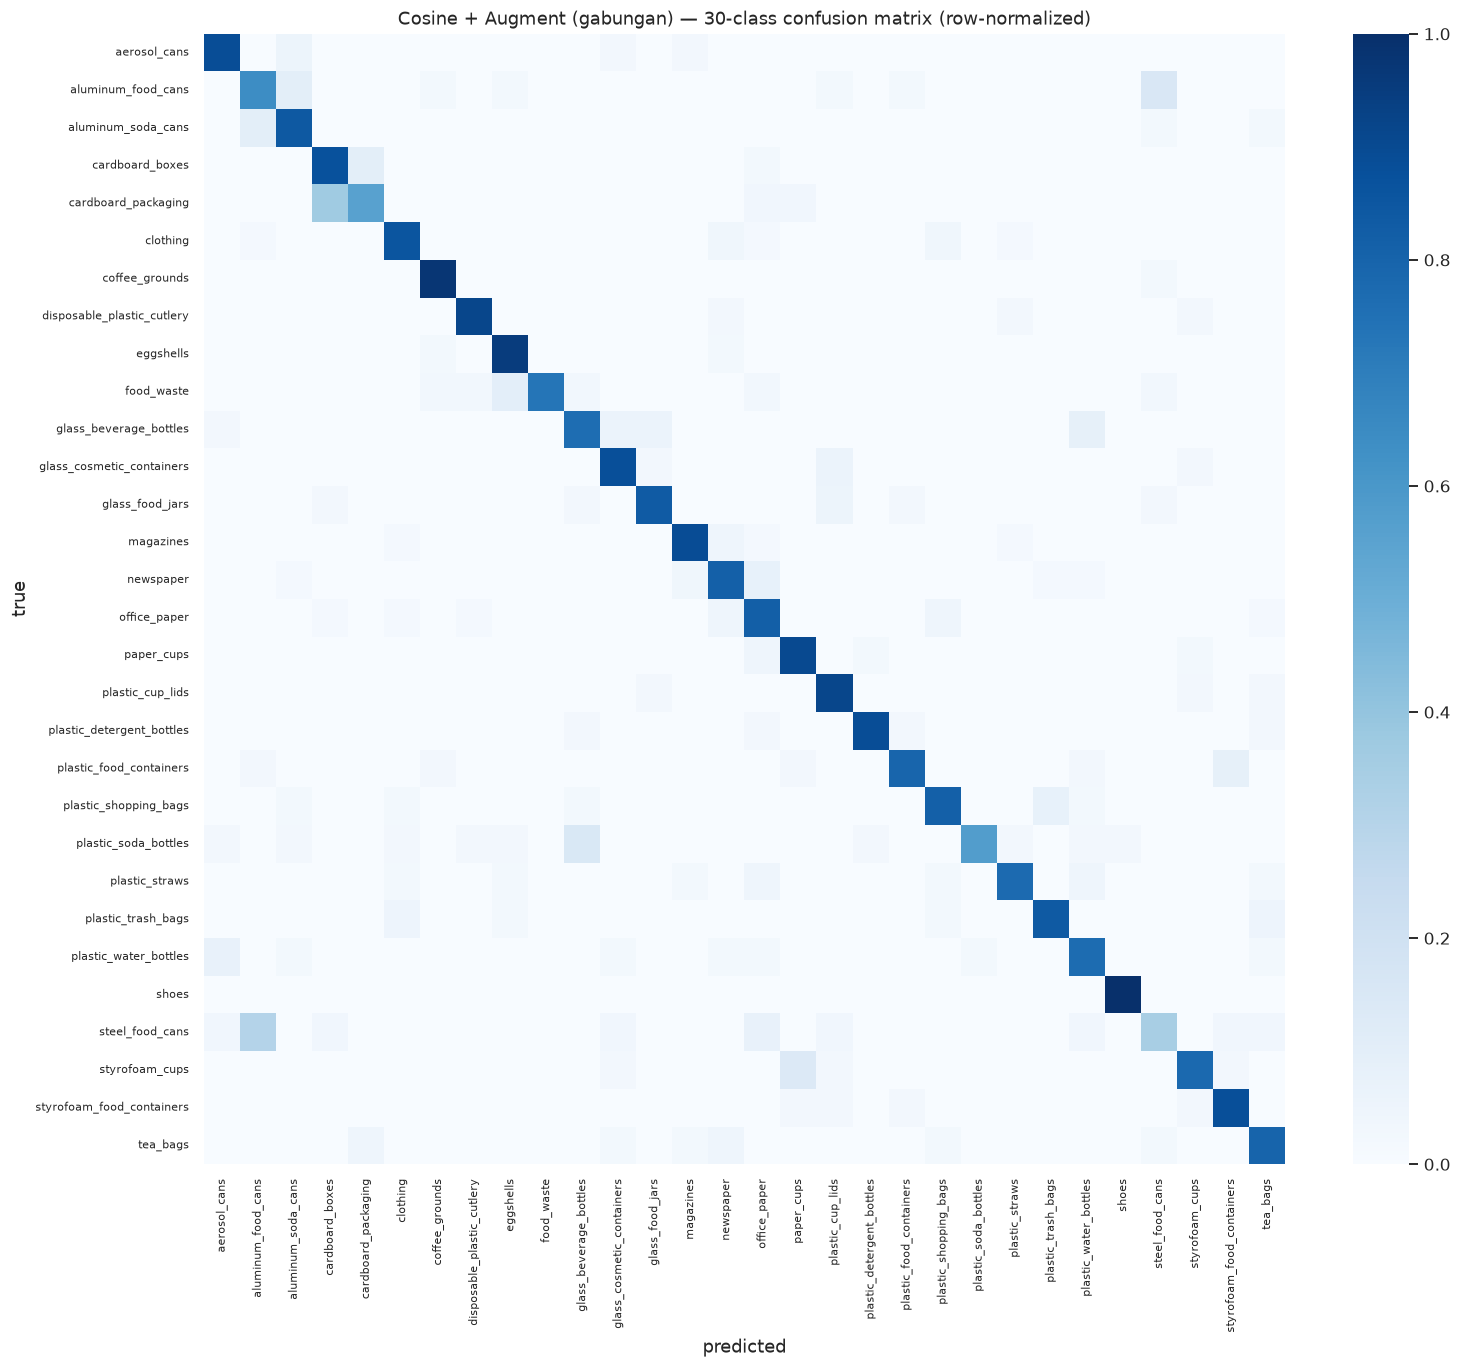

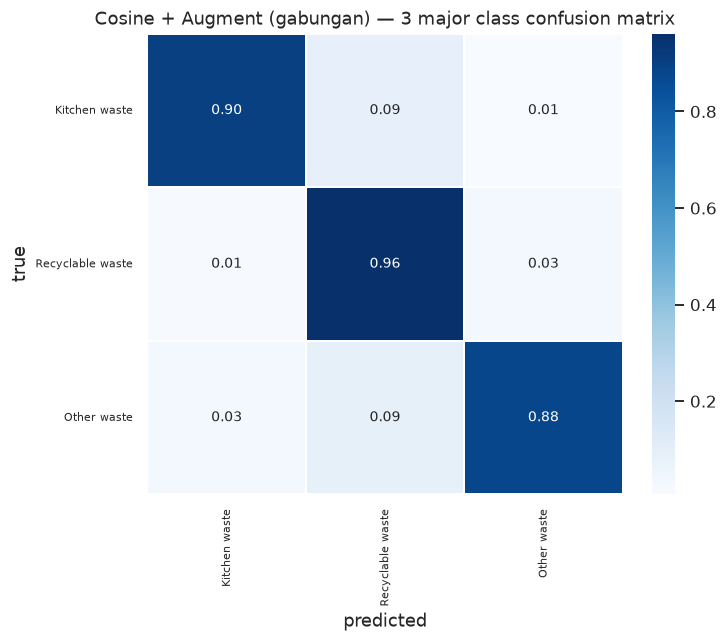

In [13]:
for name, evaluation in evaluations.items():
    metric = evaluation["metrics"]
    label = runs[name]["label"]
    plot_confusion_matrix(
        np.array(metric["confusion_matrix"]), CLASS_NAMES,
        f"{label} — 30-class confusion matrix (row-normalized)",
        FIGURE_DIR / f"{name}_confusion_30.png", normalize=True,
    )
    plot_confusion_matrix(
        np.array(metric["major_confusion_matrix"]), MAJOR_NAMES,
        f"{label} — 3 major class confusion matrix",
        FIGURE_DIR / f"{name}_confusion_major.png", normalize=True,
    )

## 10. Analisis error

Cosine + Augment (gabungan): 202 salah dari 1,133 gambar test


,true_class,pred_class,count
0,cardboard_packaging,cardboard_boxes,10
1,steel_food_cans,aluminum_food_cans,8
2,aluminum_food_cans,steel_food_cans,6
3,plastic_soda_bottles,glass_beverage_bottles,5
4,styrofoam_cups,paper_cups,5


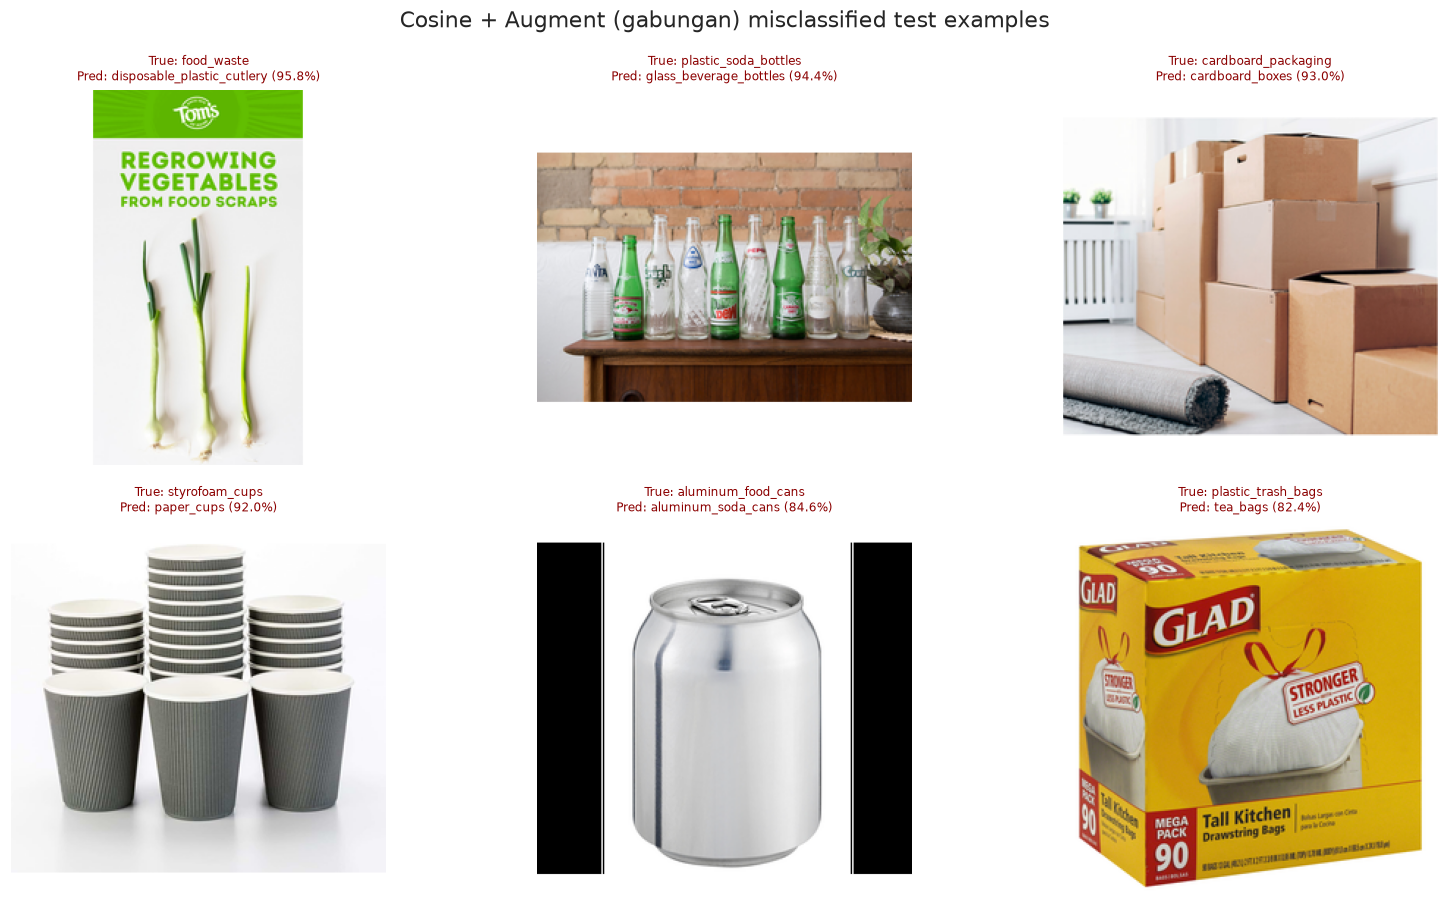

In [14]:
def build_prediction_frame(frame, probs, labels, preds):
    result = frame[["rel_path", "class_name", "source_group"]].copy()
    result["true_class"] = [CLASS_NAMES[int(i)] for i in labels]
    result["pred_class"] = [CLASS_NAMES[int(i)] for i in preds]
    result["confidence"] = probs.max(axis=1)
    result["correct"] = result["true_class"].eq(result["pred_class"])
    return result


def show_misclassified(predictions, model_name, output_stem, output_path, max_examples=6, make_figure=True):
    errors = predictions[~predictions["correct"]].sort_values("confidence", ascending=False).reset_index(drop=True)
    print(f"{model_name}: {len(errors):,} salah dari {len(predictions):,} gambar test")
    if errors.empty:
        return errors
    errors.to_csv(RESULT_DIR / f"{output_stem}_misclassified.csv", index=False)
    display(errors.groupby(["true_class", "pred_class"]).size().sort_values(ascending=False).head(5).rename("count").reset_index())
    if not make_figure:
        return errors
    examples = errors.head(max_examples)
    ncols = min(3, len(examples))
    nrows = math.ceil(len(examples) / ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(5 * ncols, 4.2 * nrows))
    axes = np.atleast_1d(axes).ravel()
    for ax, (_, row) in zip(axes, examples.iterrows()):
        with Image.open(DATA_ROOT / row["rel_path"]) as img:
            ax.imshow(img.convert("RGB"))
        ax.set_title(f"True: {row['true_class']}\nPred: {row['pred_class']} ({row['confidence'] * 100:.1f}%)", fontsize=8, color="darkred")
        ax.axis("off")
    for ax in axes[len(examples):]:
        ax.axis("off")
    fig.suptitle(f"{model_name} misclassified test examples")
    fig.tight_layout()
    fig.savefig(output_path, bbox_inches="tight")
    plt.show()
    plt.close(fig)
    return errors


best_name = max(evaluations, key=lambda k: evaluations[k]["metrics"]["accuracy"])
all_errors = {}
for name, evaluation in evaluations.items():
    predictions = build_prediction_frame(
        test_df, evaluation["probabilities"], evaluation["labels"], evaluation["predictions"]
    )
    all_errors[name] = show_misclassified(
        predictions, runs[name]["label"], name,
        FIGURE_DIR / f"{name}_misclassified_examples.png",
        make_figure=(name == best_name),
    )

## 11. Ringkasan metrik dan perbandingan

In [15]:
insight_rows = []
for name, evaluation in evaluations.items():
    metric = evaluation["metrics"]
    insight_rows.append({
        "Varian": runs[name]["label"],
        "Prefix": name,
        "Test accuracy (%)": metric["accuracy"] * 100,
        "Cross-entropy loss": metric["loss"],
        "Top-3 accuracy (%)": metric["top3_accuracy"] * 100,
        "3-class accuracy (%)": metric["major_accuracy"] * 100,
        "3-class prob accuracy (%)": metric["major_prob_accuracy"] * 100,
        "Macro F1 (30 kelas)": metric["macro_f1"],
        "Macro F1 (3 major class)": metric["major_report"]["macro avg"]["f1-score"],
        "Parameters (M)": count_parameters(evaluation["model"]) / 1e6,
    })

variant_table = pd.DataFrame(insight_rows).set_index("Varian")
display(variant_table.round(3))
variant_table.to_csv(RESULT_DIR / "mobilenetv3small_cosine_aug_metrics.csv")

# Perbandingan singkat dengan baseline yang sudah ada (jika tersedia), disimpan ke file baru
comparison = variant_table.drop(columns=["Prefix"]).copy()
comparison["Parameters (M)"] = comparison["Parameters (M)"].round(3)
baseline_path = RESULT_DIR / "model_comparison.csv"
insight_path = RESULT_DIR / "model_insights.csv"
if baseline_path.exists():
    baseline = pd.read_csv(baseline_path).set_index("Model")
    if insight_path.exists():
        extra = pd.read_csv(insight_path).set_index("Model").rename(columns={"Macro F1": "Macro F1 (30 kelas)"})
        baseline = baseline.join(extra, how="left")
    baseline = baseline.reindex(columns=comparison.columns)
    comparison = pd.concat([comparison, baseline])
# Tambahkan varian v3small A/B/C jika ada (untuk konteks, tanpa menimpa file lama)
v3_prev = RESULT_DIR / "mobilenetv3small_variants_metrics.csv"
if v3_prev.exists():
    prev = pd.read_csv(v3_prev).set_index("Varian").drop(columns=["Prefix"], errors="ignore")
    prev = prev.reindex(columns=comparison.columns)
    comparison = pd.concat([comparison, prev])
comparison = comparison[~comparison.index.duplicated(keep="first")]
comparison.to_csv(RESULT_DIR / "mobilenetv3small_cosine_aug_comparison.csv")
display(comparison.round(3))

,Prefix,Test accuracy (%),Cross-entropy loss,Top-3 accuracy (%),3-class accuracy (%),3-class prob accuracy (%),Macro F1 (30 kelas),Macro F1 (3 major class),Parameters (M)
Varian,,,,,,,,,
Cosine + Augment (gabungan),mobilenetv3small_cosine_aug,82.171,0.626,94.881,93.822,94.086,0.812,0.917,1.549


,Test accuracy (%),Cross-entropy loss,Top-3 accuracy (%),3-class accuracy (%),3-class prob accuracy (%),Macro F1 (30 kelas),Macro F1 (3 major class),Parameters (M)
Cosine + Augment (gabungan),82.171,0.626,94.881,93.822,94.086,0.812,0.917,1.549
MobileNetV2,85.172,0.465,96.117,96.205,96.558,0.844,NaN,2.262
CNN,40.071,4.341,56.664,72.021,73.786,0.392,NaN,23.911
A · baseline,80.759,0.654,92.851,92.939,93.204,0.804,0.907,1.549
B · cosine,83.407,0.618,95.322,94.969,95.146,0.826,0.933,1.549
C · augment,77.846,0.709,92.056,91.086,92.056,0.772,0.886,1.549


## 12. Simpan ringkasan (file baru)

In [16]:
variant_records = {}
for name, run in runs.items():
    metric = evaluations[name]["metrics"]
    variant_records[name] = {
        "label": run["label"],
        "config": {
            "scheduler": run["spec"].get("scheduler"),
            "label_smoothing": run["spec"].get("label_smoothing"),
            "weight_decay": run["spec"].get("weight_decay"),
            "class_weight": run["spec"].get("class_weight"),
            "augmentation": run["spec"].get("augmentation"),
        },
        "best_epoch": int(run["best_epoch"]),
        "best_val_acc": float(run["best_val_acc"]),
        "epochs_run": len(run["history"]),
        "early_stopped": len(run["history"]) < NUM_EPOCHS,
        "parameters": count_parameters(evaluations[name]["model"]),
        "metrics": {
            "accuracy": metric["accuracy"],
            "loss": metric["loss"],
            "top3_accuracy": metric["top3_accuracy"],
            "major_accuracy": metric["major_accuracy"],
            "major_prob_accuracy": metric["major_prob_accuracy"],
            "macro_f1": metric["macro_f1"],
            "weighted_f1": metric["weighted_f1"],
            "macro_f1_major": metric["major_report"]["macro avg"]["f1-score"],
            "group_accuracy": metric["group_accuracy"],
        },
        "artifacts": {
            "checkpoint": str(run["checkpoint"]),
            "full_model": str(run["full_model"]),
            "history": str(run["history_csv"]),
            "metrics": str(RESULT_DIR / f"{name}_metrics.json"),
        },
    }

summary = {
    "paper": {
        "title": "Application of MobileNetV2 to waste classification",
        "authors": "Yong, Ma, Sun, Du",
        "journal": "PLOS ONE 18(3): e0282336",
        "doi": "10.1371/journal.pone.0282336",
    },
    "arch": "mobilenet_v3_small",
    "pretrained": PRETRAINED,
    "run_name": "cosine+augment (gabungan)",
    "dataset": {
        "root": str(DATA_ROOT),
        "split_manifest": str(SPLIT_MANIFEST),
        "num_classes": NUM_CLASSES,
        "num_images": int(len(df)),
        "split_sizes": {s: int((df["split"] == s).sum()) for s in ("train", "val", "test")},
        "major_names": MAJOR_NAMES,
        "class_to_major": CLASS_TO_MAJOR,
    },
    "training": {
        "img_size": IMG_SIZE, "batch_size": BATCH_SIZE, "num_epochs": NUM_EPOCHS,
        "learning_rate": LEARNING_RATE, "momentum": MOMENTUM,
        "step_size": STEP_SIZE, "gamma": GAMMA,
        "test_batch_size": TEST_BATCH_SIZE,
        "early_stopping_patience": EARLY_STOP_PATIENCE,
        "early_stop_min_epochs": EARLY_STOP_MIN_EPOCHS,
        "seed": SEED, "device": str(DEVICE), "quick_test": QUICK_TEST,
    },
    "variants": variant_records,
    "best_variant": best_name,
    "versions": {
        "python": sys.version.split()[0],
        "torch": torch.__version__,
        "torchvision": __import__("torchvision").__version__,
        "numpy": np.__version__,
        "pandas": pd.__version__,
    },
}
summary_path = RESULT_DIR / "mobilenetv3small_cosine_aug_summary.json"
with open(summary_path, "w") as handle:
    json.dump(jsonable(summary), handle, indent=2)
print("Wrote", summary_path)
print("\nArtefak utama (prefix mobilenetv3small_cosine_aug_*) tersimpan di outputs/models, outputs/results, outputs/figures tanpa menimpa varian A/B/C.")

Wrote /mnt/home/probation-03/kel-16/Probation_IS-Lab_Team-16/outputs/results/mobilenetv3small_cosine_aug_summary.json

Artefak utama (prefix mobilenetv3small_cosine_aug_*) tersimpan di outputs/models, outputs/results, outputs/figures tanpa menimpa varian A/B/C.
